Libraries imported successfully!

===== Student Dataset =====
    Study_Hours  Attendance  Assignments Result
0             1          40            1   Fail
1             2          50            2   Fail
2             3          55            2   Fail
3             4          60            3   Fail
4             5          65            3   Pass
5             6          70            4   Pass
6             7          80            5   Pass
7             8          90            5   Pass
8             2          45            1   Fail
9             3          55            2   Fail
10            4          75            3   Pass
11            5          80            4   Pass
12            6          85            4   Pass
13            7          90            5   Pass
14            8          95            5   Pass
15            1          30            0   Fail
16            3          60            2   Fail
17            5          70            3   Pass
18            7          8

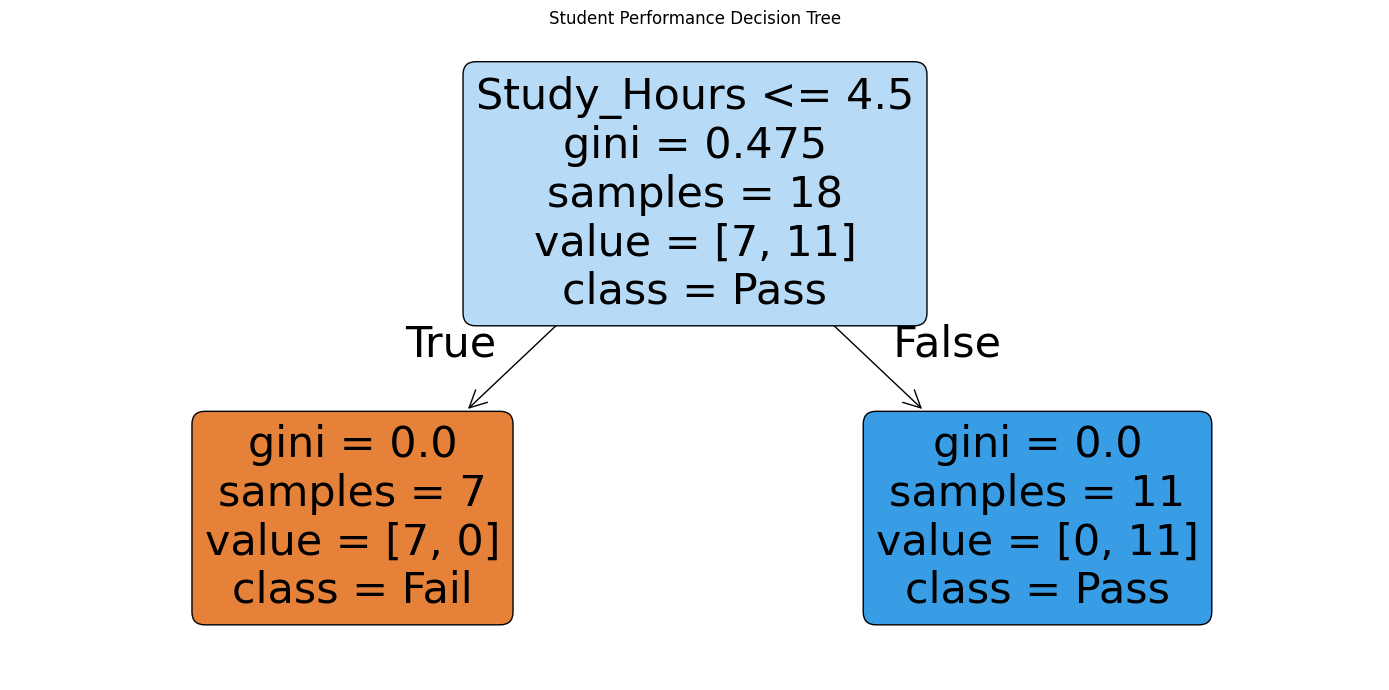

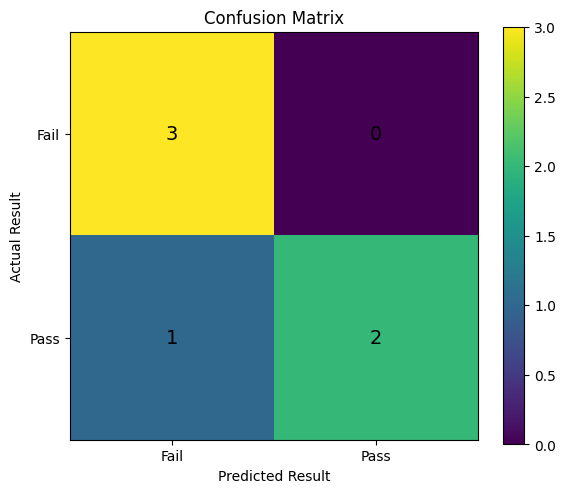

In [4]:
# Import Libraries
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report
)

print("Libraries imported successfully!")


# Create Dataset
data = {
    "Study_Hours": [
        1, 2, 3, 4, 5, 6, 7, 8,
        2, 3, 4, 5, 6, 7, 8, 1,
        3, 5, 7, 9, 2, 4, 6, 8
    ],

    "Attendance": [
        40, 50, 55, 60, 65, 70, 80, 90,
        45, 55, 75, 80, 85, 90, 95, 30,
        60, 70, 85, 95, 50, 65, 75, 90
    ],

    "Assignments": [
        1, 2, 2, 3, 3, 4, 5, 5,
        1, 2, 3, 4, 4, 5, 5, 0,
        2, 3, 5, 5, 1, 3, 4, 5
    ],

    "Result": [
        "Fail", "Fail", "Fail", "Fail", "Pass",
        "Pass", "Pass", "Pass", "Fail", "Fail",
        "Pass", "Pass", "Pass", "Pass", "Pass",
        "Fail", "Fail", "Pass", "Pass", "Pass",
        "Fail", "Fail", "Pass", "Pass"
    ]
}

df = pd.DataFrame(data)

print("\n===== Student Dataset =====")
print(df)

print("\nDataset Shape:", df.shape)


# 3. Separate Features (X) and Target (y)
X = df[[
    "Study_Hours",
    "Attendance",
    "Assignments"
]]

y = df["Result"]

print("\n===== Features (X) =====")
print(X.head())

print("\n===== Target (y) =====")
print(y.head())


# Split Data into Training and Testing Sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.25,
    random_state=42,
    stratify=y
)

print("\n===== Data Splitting =====")
print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))


# Create and Train the Model
model = DecisionTreeClassifier(
    max_depth=3,
    random_state=42
)

model.fit(X_train, y_train)

print("\nModel training completed!")


# Make Predictions
y_pred = model.predict(X_test)

print("\n===== Actual Results =====")
print(y_test.to_list())

print("\n===== Predicted Results =====")
print(y_pred)


# Evaluate Model using Accuracy
accuracy = accuracy_score(y_test, y_pred)

print("\n===== Model Accuracy =====")
print(f"Accuracy: {accuracy * 100:.2f}%")


# Confusion Matrix
cm = confusion_matrix(
    y_test,
    y_pred,
    labels=["Fail", "Pass"]
)

print("\n===== Confusion Matrix =====")
print("Labels order: Fail, Pass")
print(cm)


# Classification Report
print("\n===== Classification Report =====")

print(
    classification_report(
        y_test,
        y_pred,
        labels=["Fail", "Pass"],
        zero_division=0
    )
)


# Predict the Result of a New Student
new_student = pd.DataFrame({
    "Study_Hours": [6],
    "Attendance": [85],
    "Assignments": [4]
})

prediction = model.predict(new_student)

print("\n===== New Student Prediction =====")
print("Study Hours: 6")
print("Attendance: 85%")
print("Assignments: 4")
print("Predicted Result:", prediction[0])


# Visualize the Decision Tree
plt.figure(figsize=(14, 7))

plot_tree(
    model,
    feature_names=X.columns,
    class_names=model.classes_,
    filled=True,
    rounded=True
)

plt.title("Student Performance Decision Tree")
plt.tight_layout()
plt.show()


# Visualize the Confusion Matrix
plt.figure(figsize=(6, 5))

plt.imshow(cm, interpolation="nearest")
plt.title("Confusion Matrix")
plt.colorbar()

plt.xticks([0, 1], ["Fail", "Pass"])
plt.yticks([0, 1], ["Fail", "Pass"])

plt.xlabel("Predicted Result")
plt.ylabel("Actual Result")

for i in range(2):
    for j in range(2):
        plt.text(
            j,
            i,
            str(cm[i, j]),
            ha="center",
            va="center",
            fontsize=14
        )

plt.tight_layout()
plt.show()